# Comparative Study and Implementation of Generative AI Models
## Comparative Study and Practical Analysis of Generative AI Models

**Group Members:**  
- **Parth Kitchloo** — PRN: 202401110014
- **Ragav Sharma** — PRN: 202401110012
- **Gufran Shah** — PRN: 202401110011
- **Sandeep Kotwal** — PRN: 202401110052  
**Branch / Batch:** AIML / A2  
**Assignment:** AI-Assisted Comparative Study and Implementation of Generative AI Models

> **How to use:** Upload this notebook to Google Colab, select **Runtime → Change runtime type → T4 GPU** (if available), then use **Runtime → Run all**. The notebook trains small demonstration models on MNIST (handwritten digits) for reliable, compact reconstruction/generation experiments, and uses nature/wildlife prompts for Stable Diffusion. The AE/VAE reconstruction and DCGAN demonstrations use MNIST handwritten digits; Stable Diffusion uses nature/wildlife prompts. This is a dataset difference to mention in your analysis.
>
> **Important:** The notebook records real outputs from your run. Do not report expected behavior as observed results. Stable Diffusion may require a Hugging Face account/token and model licence acceptance; if that step fails, follow the instructions in the Stable Diffusion section.

## 1. Aim and Objectives

**Aim:** To study and compare Autoencoder (AE), Variational Autoencoder (VAE), Deep Convolutional GAN (DCGAN), and a pretrained diffusion model (Stable Diffusion) through image reconstruction and image generation.

**Objectives**
1. Implement and evaluate AE reconstruction.
2. Implement and evaluate VAE reconstruction and latent-space sampling.
3. Train a compact DCGAN and inspect generated samples.
4. Generate prompt-conditioned images using a pretrained Stable Diffusion model.
5. compare working principles, architectures, output characteristics, advantages, limitations, and applications.
6. Save experimental figures, measured metrics, and observations for use in a separately prepared report and presentation.

**Conceptual distinction:** AE and VAE are evaluated here primarily for reconstruction; DCGAN and Stable Diffusion are evaluated for generation. A VAE can also generate new samples by sampling its latent distribution.

## 2. Runtime and dependency setup

This cell avoids reinstalling PyTorch, because Colab normally includes a compatible build. It installs only supporting packages if needed.

In [1]:
import os, sys, json, time, math, random, platform, subprocess, textwrap, warnings
from pathlib import Path

SEED = 42
random.seed(SEED)
np_seed = SEED
os.environ["PYTHONHASHSEED"] = str(SEED)

try:
    import torch
    import torchvision
except Exception as e:
    raise RuntimeError(
        "PyTorch/Torchvision could not be imported in this runtime. "
        "In Colab, select Runtime > Change runtime type > GPU, then Runtime > Restart session "
        "and run again. Do not install large CUDA wheels manually unless necessary."
    ) from e

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected. The AE/VAE/DCGAN demo can run on CPU but will be slower.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
# Install supporting libraries without forcing a PyTorch reinstall.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "matplotlib", "pillow", "nbformat", "python-docx", "python-pptx", "reportlab"
])
print("Supporting packages are ready.")

Supporting packages are ready.


## 3. Imports and output folders
All generated figures and result files are saved under `assignment_outputs/`.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from torchvision import datasets, transforms
from torch import nn
from torch.utils.data import DataLoader, Subset

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("assignment_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS = {
     "project_title": "Comparative Study and Practical Analysis of Generative AI Models",
    "group_members": [
        {"name": "Parth Kitchloo", "prn": "202401110014"},
        {"name": "Ragav Sharma", "prn": "202401110012"},
        {"name": "Gufran Shah", "prn": "202401110011"},
        {"name": "Sandeep Kotwal", "prn": "202401110052"}
    ],
    "student_name": "Parth Kitchloo",
    "prn": "202401110014",
    "branch": "AIML",
    "batch": "A2",
    "runtime": {"python": sys.version.split()[0], "torch": torch.__version__, "device": str(DEVICE)},
    "experiments": {},
    "prompts": [],
    "limitations": []
}
print("Device:", DEVICE)
print("Output folder:", OUTPUT_DIR.resolve())

Device: cuda
Output folder: /content/assignment_outputs


## 4. Dataset: MNIST for compact reconstruction and GAN experiments

MNIST is a small, widely used dataset that is practical for a short Colab demonstration. It contains handwritten digits, not wildlife photographs; it is used here to keep AE/VAE/DCGAN training manageable. Stable Diffusion prompts use the nature-and-wildlife theme. State this dataset/theme distinction honestly in your report.

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.97MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 143kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.11MB/s]

Training samples: 12000 | Test samples: 2000


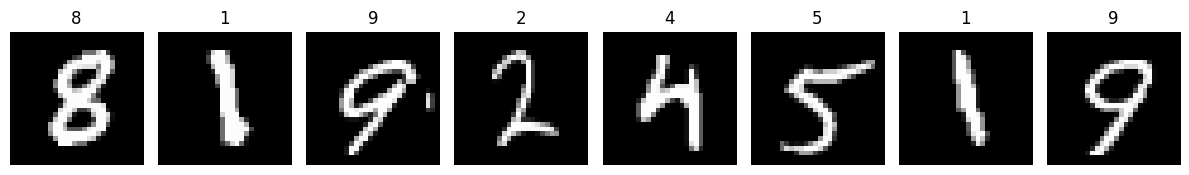

In [4]:
BATCH_SIZE = 128
MAX_TRAIN_SAMPLES = 12000   # lower this to 4000 if runtime is slow
MAX_TEST_SAMPLES = 2000
EPOCHS_AE = 10
EPOCHS_VAE = 10
EPOCHS_DCGAN = 10

transform = transforms.Compose([
    transforms.ToTensor(),  # [0,1]
])

try:
    train_full = datasets.MNIST(root="data", train=True, download=True, transform=transform)
    test_full = datasets.MNIST(root="data", train=False, download=True, transform=transform)
except Exception as e:
    raise RuntimeError(
        "MNIST download failed. Check Colab internet access and rerun this cell. "
        "If downloads remain unavailable, upload an MNIST-compatible dataset or use another public dataset."
    ) from e

train_set = Subset(train_full, range(min(MAX_TRAIN_SAMPLES, len(train_full))))
test_set = Subset(test_full, range(min(MAX_TEST_SAMPLES, len(test_full))))
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

print(f"Training samples: {len(train_set)} | Test samples: {len(test_set)}")
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, im, lab in zip(axes, images[:8], labels[:8]):
    ax.imshow(im.squeeze(), cmap="gray")
    ax.set_title(str(int(lab)))
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "dataset_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Model 1 — Autoencoder (AE)

An Autoencoder encodes an input into a compact latent representation and decodes it to reconstruct the input. We use a small fully connected network on 28×28 MNIST images and optimize mean squared error (MSE).

In [5]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 256), nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 28*28), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z).view(-1, 1, 28, 28)

def train_reconstruction_model(model, loader, epochs, loss_fn, optimizer, name):
    model.to(DEVICE)
    history = []
    for epoch in range(epochs):
        model.train()
        total, count = 0.0, 0
        for x, _ in loader:
            x = x.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            recon = model(x)
            loss = loss_fn(recon, x)
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0)
            count += x.size(0)
        avg = total / max(count, 1)
        history.append(avg)
        print(f"{name} | epoch {epoch+1}/{epochs} | loss={avg:.6f}")
    return history

ae = Autoencoder(latent_dim=32)
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
ae_history = train_reconstruction_model(ae, train_loader, EPOCHS_AE, nn.MSELoss(), ae_optimizer, "AE")
RESULTS["experiments"]["AE"] = {"epochs": EPOCHS_AE, "train_mse_by_epoch": ae_history}

AE | epoch 1/10 | loss=0.089489
AE | epoch 2/10 | loss=0.056921
AE | epoch 3/10 | loss=0.042849
AE | epoch 4/10 | loss=0.034817
AE | epoch 5/10 | loss=0.030923
AE | epoch 6/10 | loss=0.028311
AE | epoch 7/10 | loss=0.026269
AE | epoch 8/10 | loss=0.024761
AE | epoch 9/10 | loss=0.023398
AE | epoch 10/10 | loss=0.022156


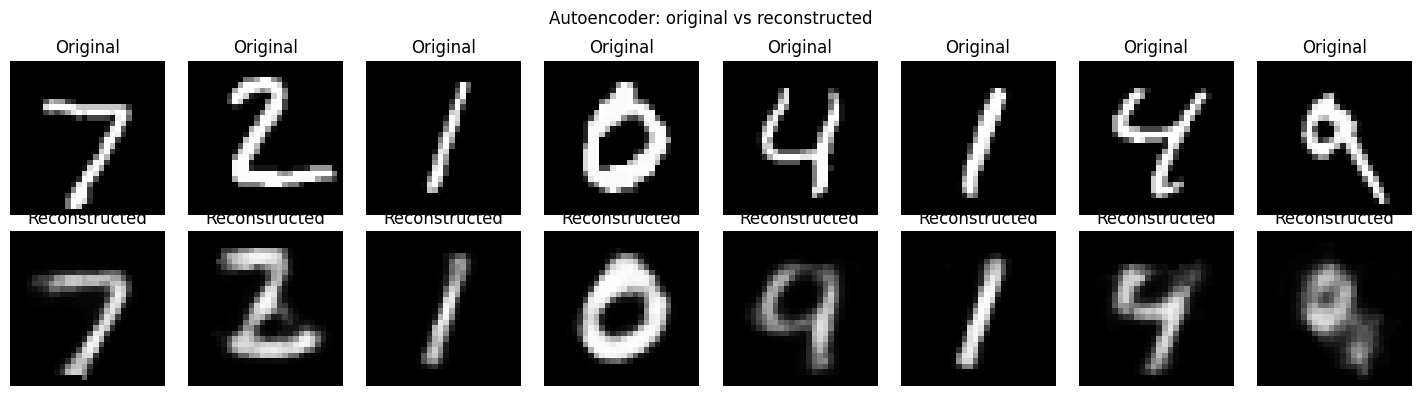

AE test-batch reconstruction MSE: 0.018874


In [6]:
def plot_reconstructions(model, loader, filename, title, n=8):
    model.eval()
    x, _ = next(iter(loader))
    x = x[:n].to(DEVICE)
    with torch.no_grad():
        recon = model(x).cpu()
    x = x.cpu()
    fig, axes = plt.subplots(2, n, figsize=(1.8*n, 4))
    for i in range(n):
        axes[0, i].imshow(x[i].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[0, i].set_title("Original")
        axes[1, i].imshow(recon[i].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].set_title("Reconstructed")
        axes[0, i].axis("off"); axes[1, i].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    path = FIG_DIR / filename
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    mse = float(torch.mean((recon - x) ** 2).item())
    return mse, str(path)

ae_test_mse, ae_fig = plot_reconstructions(ae, test_loader, "ae_reconstructions.png", "Autoencoder: original vs reconstructed")
RESULTS["experiments"]["AE"]["test_reconstruction_mse"] = ae_test_mse
RESULTS["experiments"]["AE"]["figure"] = ae_fig
print(f"AE test-batch reconstruction MSE: {ae_test_mse:.6f}")

## 6. Model 2 — Variational Autoencoder (VAE)

A VAE predicts a latent mean and log-variance, samples a latent vector using the reparameterization trick, and optimizes reconstruction loss plus KL divergence. This regularizes the latent space and makes sampling meaningful.

In [7]:
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.fc2 = nn.Linear(latent_dim, 256)
        self.fc3 = nn.Linear(256, 28*28)
    def encode(self, x):
        h = torch.relu(self.fc1(x.view(x.size(0), -1)))
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    def decode(self, z):
        return torch.sigmoid(self.fc3(torch.relu(self.fc2(z)))).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss(recon, x, mu, logvar):
    recon_loss = nn.functional.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon_loss + kl, recon_loss, kl

vae = VAE(latent_dim=16).to(DEVICE)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_history = []
for epoch in range(EPOCHS_VAE):
    vae.train()
    total, count = 0.0, 0
    for x, _ in train_loader:
        x = x.to(DEVICE)
        vae_optimizer.zero_grad(set_to_none=True)
        recon, mu, logvar = vae(x)
        loss, _, _ = vae_loss(recon, x, mu, logvar)
        loss.backward()
        vae_optimizer.step()
        total += loss.item() * x.size(0)
        count += x.size(0)
    avg = total / max(count, 1)
    vae_history.append(avg)
    print(f"VAE | epoch {epoch+1}/{EPOCHS_VAE} | total loss={avg:.6f}")
RESULTS["experiments"]["VAE"] = {"epochs": EPOCHS_VAE, "train_total_loss_by_epoch": vae_history}

VAE | epoch 1/10 | total loss=248.556259
VAE | epoch 2/10 | total loss=172.596933
VAE | epoch 3/10 | total loss=151.901239
VAE | epoch 4/10 | total loss=142.131150
VAE | epoch 5/10 | total loss=135.135496
VAE | epoch 6/10 | total loss=130.177571
VAE | epoch 7/10 | total loss=126.576652
VAE | epoch 8/10 | total loss=123.665638
VAE | epoch 9/10 | total loss=121.435857
VAE | epoch 10/10 | total loss=119.692467


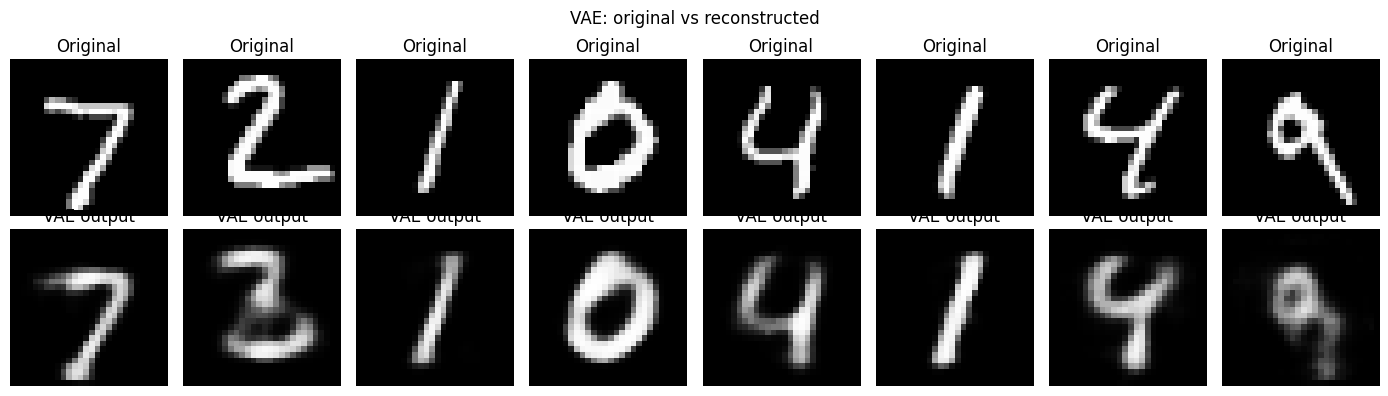

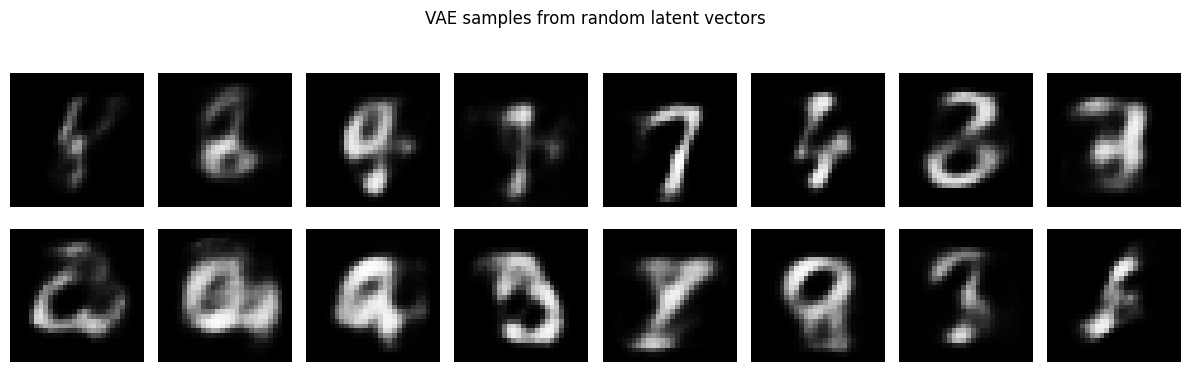

VAE test-batch MSE: 0.018648


In [8]:
vae.eval()
x, _ = next(iter(test_loader))
x = x[:8].to(DEVICE)
with torch.no_grad():
    recon, mu, logvar = vae(x)
x_cpu, recon_cpu = x.cpu(), recon.cpu()
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    axes[0, i].imshow(x_cpu[i].squeeze(), cmap="gray", vmin=0, vmax=1); axes[0, i].set_title("Original")
    axes[1, i].imshow(recon_cpu[i].squeeze(), cmap="gray", vmin=0, vmax=1); axes[1, i].set_title("VAE output")
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.suptitle("VAE: original vs reconstructed")
plt.tight_layout()
vae_fig = FIG_DIR / "vae_reconstructions.png"
plt.savefig(vae_fig, dpi=160, bbox_inches="tight")
plt.show()

vae_test_mse = float(torch.mean((recon_cpu - x_cpu) ** 2).item())
RESULTS["experiments"]["VAE"]["test_reconstruction_mse"] = vae_test_mse
RESULTS["experiments"]["VAE"]["figure"] = str(vae_fig)

with torch.no_grad():
    z = torch.randn(16, 16, device=DEVICE)
    samples = vae.decode(z).cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, im in zip(axes.flat, samples):
    ax.imshow(im.squeeze(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
plt.suptitle("VAE samples from random latent vectors")
plt.tight_layout()
vae_samples_fig = FIG_DIR / "vae_latent_samples.png"
plt.savefig(vae_samples_fig, dpi=160, bbox_inches="tight")
plt.show()
RESULTS["experiments"]["VAE"]["latent_samples_figure"] = str(vae_samples_fig)
print(f"VAE test-batch MSE: {vae_test_mse:.6f}")

## 7. Model 3 — DCGAN

DCGAN trains a generator to create images from random noise and a discriminator to distinguish real images from generated ones. This compact model uses 28×28 grayscale MNIST images, resized/normalized to the range [-1, 1]. Short training may produce imperfect or repetitive images; that is a valid limitation to discuss.

In [9]:
class Generator(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128*7*7, 1),
            nn.Sigmoid()
        )
    def forward(self, x): return self.net(x)

Z_DIM = 64
G = Generator(Z_DIM).to(DEVICE)
D = Discriminator().to(DEVICE)
criterion = nn.BCELoss()
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
gan_history = []
gan_loader = DataLoader(train_set, batch_size=128, shuffle=True, drop_last=True, num_workers=2, pin_memory=torch.cuda.is_available())

for epoch in range(EPOCHS_DCGAN):
    G.train(); D.train()
    running_d, running_g, n_batches = 0.0, 0.0, 0
    for real, _ in gan_loader:
        real = (real.to(DEVICE) * 2.0) - 1.0
        b = real.size(0)
        real_labels = torch.ones(b, 1, device=DEVICE)
        fake_labels = torch.zeros(b, 1, device=DEVICE)

        # Update discriminator
        optD.zero_grad(set_to_none=True)
        out_real = D(real)
        loss_real = criterion(out_real, real_labels)
        noise = torch.randn(b, Z_DIM, 1, 1, device=DEVICE)
        fake = G(noise)
        out_fake = D(fake.detach())
        loss_fake = criterion(out_fake, fake_labels)
        lossD = loss_real + loss_fake
        lossD.backward()
        optD.step()

        # Update generator
        optG.zero_grad(set_to_none=True)
        out_fake_for_g = D(fake)
        lossG = criterion(out_fake_for_g, real_labels)
        lossG.backward()
        optG.step()

        running_d += lossD.item(); running_g += lossG.item(); n_batches += 1
    d_avg = running_d / max(n_batches, 1)
    g_avg = running_g / max(n_batches, 1)
    gan_history.append({"discriminator_loss": d_avg, "generator_loss": g_avg})
    print(f"DCGAN | epoch {epoch+1}/{EPOCHS_DCGAN} | D loss={d_avg:.4f} | G loss={g_avg:.4f}")

RESULTS["experiments"]["DCGAN"] = {"epochs": EPOCHS_DCGAN, "losses_by_epoch": gan_history}

DCGAN | epoch 1/10 | D loss=0.6166 | G loss=2.1622
DCGAN | epoch 2/10 | D loss=0.9463 | G loss=1.2756
DCGAN | epoch 3/10 | D loss=0.9173 | G loss=1.1494
DCGAN | epoch 4/10 | D loss=0.8459 | G loss=1.2507
DCGAN | epoch 5/10 | D loss=0.7871 | G loss=1.3510
DCGAN | epoch 6/10 | D loss=0.7589 | G loss=1.4294
DCGAN | epoch 7/10 | D loss=0.7075 | G loss=1.4930
DCGAN | epoch 8/10 | D loss=0.7191 | G loss=1.5438
DCGAN | epoch 9/10 | D loss=0.6780 | G loss=1.5732
DCGAN | epoch 10/10 | D loss=0.6663 | G loss=1.6046


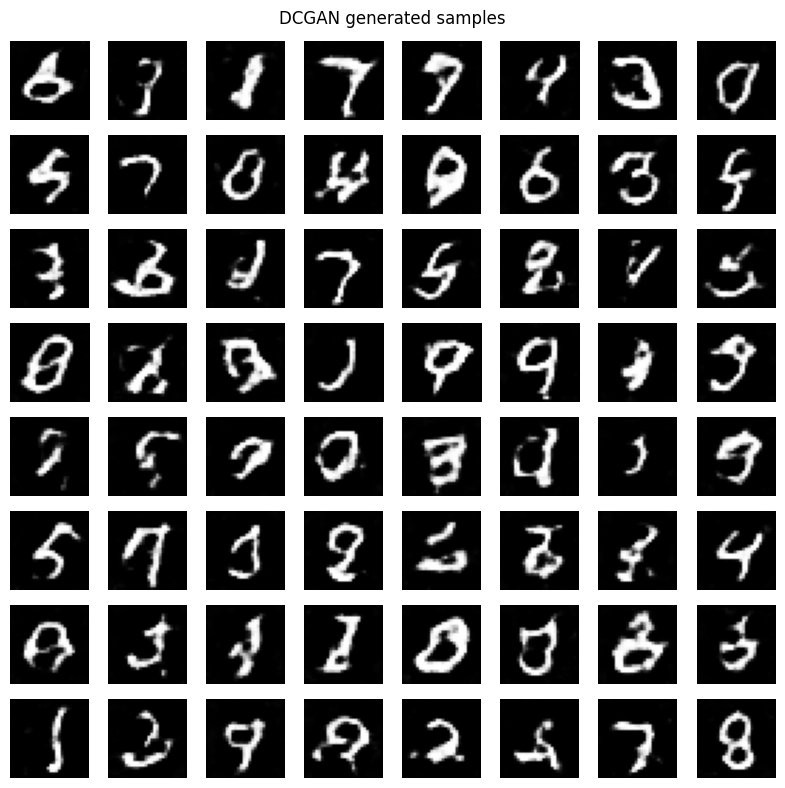

In [10]:
G.eval()
with torch.no_grad():
    fixed_noise = torch.randn(64, Z_DIM, 1, 1, device=DEVICE)
    fake = G(fixed_noise).cpu()
fake = (fake + 1.0) / 2.0
fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for ax, im in zip(axes.flat, fake):
    ax.imshow(im.squeeze(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
plt.suptitle("DCGAN generated samples")
plt.tight_layout()
dcgan_fig = FIG_DIR / "dcgan_generated_samples.png"
plt.savefig(dcgan_fig, dpi=160, bbox_inches="tight")
plt.show()
RESULTS["experiments"]["DCGAN"]["figure"] = str(dcgan_fig)

## 8. Model 4 — Pretrained Stable Diffusion

Stable Diffusion uses iterative denoising conditioned on text prompts. This is the only section that generates nature/wildlife imagery directly in this notebook.

**Access note:** Hugging Face model access, licence acceptance, model availability, and memory requirements can change. If loading fails, read the error message. If the selected model requires access approval, accept its licence on Hugging Face and add a token to Colab Secrets under the name `HF_TOKEN`. You can also change `SD_MODEL_ID` to another model you are authorized to use.

The model may take several minutes to download and generate images. A GPU is strongly recommended.

In [11]:
# Install Diffusers support. This cell does not intentionally replace torch.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "diffusers", "transformers", "accelerate", "safetensors"
])
print("Diffusers dependencies installed.")

Diffusers dependencies installed.


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/20 [00:00<?, ?it/s]

Saved: assignment_outputs/figures/stable_diffusion_1.png | prompt: A realistic wildlife photograph of a Bengal tiger walking through a lush green forest, natural light, detailed fur


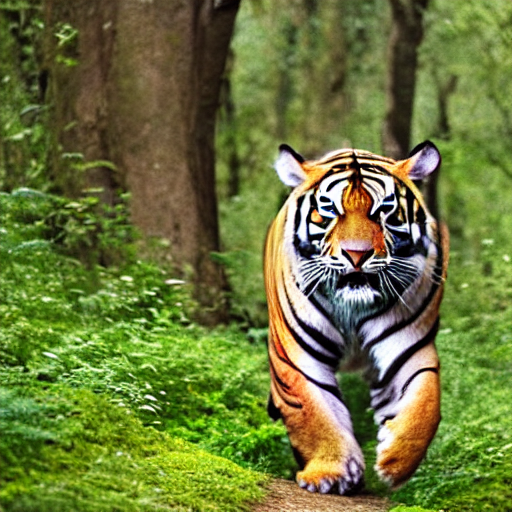

  0%|          | 0/20 [00:00<?, ?it/s]

Saved: assignment_outputs/figures/stable_diffusion_2.png | prompt: A colorful kingfisher perched on a branch beside a clear river, wildlife photography, sharp details


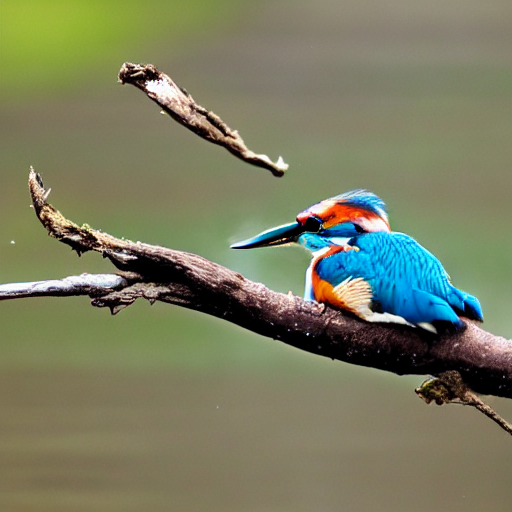

  0%|          | 0/20 [00:00<?, ?it/s]

Saved: assignment_outputs/figures/stable_diffusion_3.png | prompt: A misty mountain landscape at sunrise, layered mountains, cinematic natural light, realistic photography


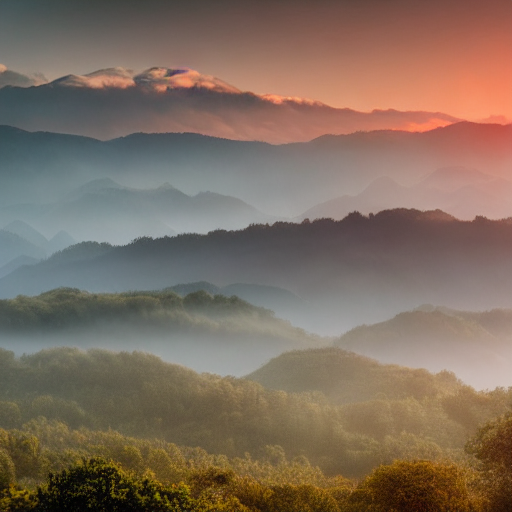

  0%|          | 0/20 [00:00<?, ?it/s]

Saved: assignment_outputs/figures/stable_diffusion_4.png | prompt: A field of wildflowers after rainfall, macro photography, detailed petals, soft morning light


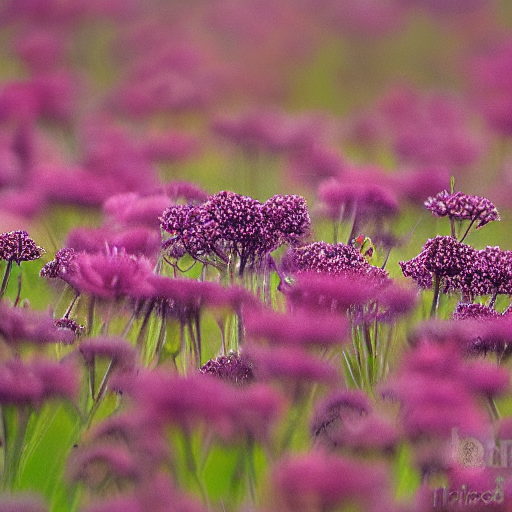

In [12]:
SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
SD_PROMPTS = [
    "A realistic wildlife photograph of a Bengal tiger walking through a lush green forest, natural light, detailed fur",
    "A colorful kingfisher perched on a branch beside a clear river, wildlife photography, sharp details",
    "A misty mountain landscape at sunrise, layered mountains, cinematic natural light, realistic photography",
    "A field of wildflowers after rainfall, macro photography, detailed petals, soft morning light"
]
RESULTS["prompts"] = SD_PROMPTS

# Read a token from Colab Secrets when available; otherwise attempt public access.
hf_token = None
try:
    from google.colab import userdata
    try:
        hf_token = userdata.get("HF_TOKEN")
    except Exception:
        hf_token = None
except Exception:
    pass

sd_success = False
sd_error = None
sd_images = []
try:
    from diffusers import StableDiffusionPipeline
    if not torch.cuda.is_available():
        print("WARNING: Stable Diffusion needs substantial memory; no GPU detected. Attempting load may fail.")
    pipe = StableDiffusionPipeline.from_pretrained(
        SD_MODEL_ID,
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        token=hf_token,
        safety_checker=None
    )
    pipe = pipe.to(DEVICE)
    if torch.cuda.is_available():
        pipe.enable_attention_slicing()
    for i, prompt in enumerate(SD_PROMPTS, start=1):
        generator = torch.Generator(device=DEVICE).manual_seed(SEED + i)
        image = pipe(
            prompt,
            num_inference_steps=20,
            guidance_scale=7.0,
            height=512,
            width=512,
            generator=generator
        ).images[0]
        path = FIG_DIR / f"stable_diffusion_{i}.png"
        image.save(path)
        sd_images.append(str(path))
        print(f"Saved: {path} | prompt: {prompt}")
        display(image)
    sd_success = True
except Exception as e:
    sd_error = repr(e)
    print("Stable Diffusion could not complete in this runtime.")
    print("Actual error:", sd_error)
    print("\nTroubleshooting:")
    print("1. Confirm GPU runtime is enabled.")
    print("2. If the model requires access, accept its licence on Hugging Face.")
    print("3. Add a Hugging Face read token to Colab Secrets named HF_TOKEN.")
    print("4. If the model ID is unavailable, update SD_MODEL_ID to a currently accessible model.")
    print("5. If out-of-memory occurs, use fewer prompts, lower resolution, or fewer inference steps.")
    RESULTS["limitations"].append("Stable Diffusion generation failed: " + sd_error)

RESULTS["experiments"]["Stable Diffusion"] = {
    "model_id": SD_MODEL_ID,
    "success": sd_success,
    "images": sd_images,
    "error": sd_error,
    "settings": {"num_inference_steps": 20, "guidance_scale": 7.0, "height": 512, "width": 512}
}

## 9. Comparative analysis

The table below describes the general design of the models. Fill the observations column only after inspecting the actual outputs from your run.

In [13]:
comparison_rows = [
    ["Autoencoder (AE)", "Encoder compresses image; decoder reconstructs it", "Reconstruction", "MSE in this notebook", "Can learn compact representations; simple training", "May blur or lose fine details; does not inherently sample a well-structured latent distribution"],
    ["Variational Autoencoder (VAE)", "Encoder estimates latent mean/variance; decoder reconstructs sampled latent", "Reconstruction and latent sampling", "Reconstruction + KL divergence", "Structured probabilistic latent space; can sample new outputs", "Outputs may be blurry; quality depends on model and training"],
    ["DCGAN", "Generator competes with discriminator in adversarial training", "Generation from random noise", "Generator/discriminator adversarial losses", "Can learn realistic samples with sufficient data/training", "Training instability, artifacts, mode collapse; short runs may be weak"],
    ["Stable Diffusion", "Text-conditioned iterative denoising of latent noise", "Prompt-conditioned generation", "Qualitative inspection in this notebook", "High-detail, prompt-guided image generation", "Resource-intensive; prompt sensitivity, access/licence and model limitations"]
]
for row in comparison_rows:
    print(" | ".join(row))
    print("-" * 100)

RESULTS["comparison_table"] = comparison_rows

Autoencoder (AE) | Encoder compresses image; decoder reconstructs it | Reconstruction | MSE in this notebook | Can learn compact representations; simple training | May blur or lose fine details; does not inherently sample a well-structured latent distribution
----------------------------------------------------------------------------------------------------
Variational Autoencoder (VAE) | Encoder estimates latent mean/variance; decoder reconstructs sampled latent | Reconstruction and latent sampling | Reconstruction + KL divergence | Structured probabilistic latent space; can sample new outputs | Outputs may be blurry; quality depends on model and training
----------------------------------------------------------------------------------------------------
DCGAN | Generator competes with discriminator in adversarial training | Generation from random noise | Generator/discriminator adversarial losses | Can learn realistic samples with sufficient data/training | Training instability, art

## 10. Record your observations and conclusion

Use the actual saved figures and printed metrics. Do not simply copy the expected behavior below as if it were observed.

In [14]:
observations = {
    "AE": "Write what you actually see in ae_reconstructions.png. Mention visible detail loss or reconstruction quality.",
    "VAE": "Write what you actually see in vae_reconstructions.png and vae_latent_samples.png.",
    "DCGAN": "Write what you actually see in dcgan_generated_samples.png. Mention recognizability, variety, and artifacts.",
    "Stable Diffusion": (
        "Write what you actually see in the saved wildlife images."
        if sd_success else
        "Not observed: Stable Diffusion did not complete in this runtime. Record the actual error and retry in Colab."
    )
}
RESULTS["observations"] = observations
for model, note in observations.items():
    print(f"{model}: {note}")

print("\nActual reconstruction metrics:")
print("AE test-batch MSE:", RESULTS["experiments"]["AE"].get("test_reconstruction_mse"))
print("VAE test-batch MSE:", RESULTS["experiments"]["VAE"].get("test_reconstruction_mse"))
print("\nImportant: MSE values from AE and VAE are only directly comparable when the same test inputs and compatible reconstruction-loss interpretation are used.")

AE: Write what you actually see in ae_reconstructions.png. Mention visible detail loss or reconstruction quality.
VAE: Write what you actually see in vae_reconstructions.png and vae_latent_samples.png.
DCGAN: Write what you actually see in dcgan_generated_samples.png. Mention recognizability, variety, and artifacts.
Stable Diffusion: Write what you actually see in the saved wildlife images.

Actual reconstruction metrics:
AE test-batch MSE: 0.01887405291199684
VAE test-batch MSE: 0.018648304045200348

Important: MSE values from AE and VAE are only directly comparable when the same test inputs and compatible reconstruction-loss interpretation are used.


In [15]:
# Save the real experiment metrics and observations as JSON only.
# This notebook does not generate the report or presentation.
results_path = OUTPUT_DIR / "results.json"
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, indent=2, default=str)
print("Saved experiment results:", results_path)


Saved experiment results: assignment_outputs/results.json
